# Noise generation v2 (SD302b)
Kept from v1: clean-target extraction, split reuse (`b6000_split.csv`), per-image deterministic seeds, NFIQ2-guided retry, validation, manifest.
New: Gaussian noise (sensor), multi-octave Perlin background clutter, mild blur back in the mix. Output goes to `noisy_500_v2`.

In [ ]:
import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'nbis-python'])
import os, io, glob, zlib, zipfile, json, shutil
import numpy as np, pandas as pd
from pathlib import Path
from PIL import Image, ImageDraw
from scipy import ndimage as ndi
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from google.colab import drive
drive.mount('/content/drive')

PROJECT   = Path('/content/drive/MyDrive/NIST/noise_project')
CLEAN_DIR = PROJECT / 'clean_500'          # reused from v1 (files that exist are skipped)
NOISY_DIR = PROJECT / 'noisy_500_v2'       # new output folder, v1 is not touched
SPLIT_CSV = PROJECT / 'b6000_split.csv'    # split is NOT recreated, same train/val/test as all other experiments
for d in (CLEAN_DIR, NOISY_DIR):
    d.mkdir(parents=True, exist_ok=True)
assert SPLIT_CSV.exists(), "b6000_split.csv not found, do not create a new split"

CFG = dict(seed=2026, clean_min=60)

zip_b = '/content/drive/MyDrive/NIST/sd302b.zip'
if not os.path.exists(zip_b):
    zip_b = glob.glob('/content/drive/**/sd302b.zip', recursive=True)[0]
print("zip_b:", zip_b)

Mounted at /content/drive
zip_b: /content/drive/MyDrive/NIST/sd302b.zip


In [ ]:
sp = pd.read_csv(SPLIT_CSV, dtype={'participant': str, 'key': str})
clean = sp[sp['nfiq2'] >= CFG['clean_min']].copy()
print("clean images:", len(clean))
print(pd.crosstab(clean['device'], clean['split']))

with zipfile.ZipFile(zip_b) as zb:
    for _, r in tqdm(clean.iterrows(), total=len(clean)):
        out = CLEAN_DIR / r['device'] / f"{r['key']}.png"
        if out.exists():
            continue
        out.parent.mkdir(parents=True, exist_ok=True)
        out.write_bytes(zb.read(r['zip_member']))      # copied as-is, no re-encoding

clean['clean_path'] = clean.apply(lambda r: str(CLEAN_DIR / r['device'] / f"{r['key']}.png"), axis=1)
clean.to_csv(PROJECT / 'clean_list.csv', index=False)

def load(p):
    return np.asarray(Image.open(p).convert('L'))

chk = clean.sample(60, random_state=0)
sizes = [(r['device'], Image.open(r['clean_path']).size) for _, r in chk.iterrows()]
print(pd.Series(sizes).value_counts().head(12))

clean images: 2490
split   test  train  val
device                  
R         60    314   85
S         93    502   83
U        104    477  123
V         81    471   97


  0%|          | 0/2490 [00:00<?, ?it/s]

(U, (800, 750))    18
(V, (800, 750))    17
(S, (266, 440))     1
(S, (256, 409))     1
(S, (256, 432))     1
(S, (293, 444))     1
(S, (256, 385))     1
(S, (289, 456))     1
(S, (293, 456))     1
(S, (317, 396))     1
(S, (256, 464))     1
(R, (346, 491))     1
Name: count, dtype: int64


In [ ]:
# ================= helpers =================
def _lowfreq(shape, sigma, rng):
    n = ndi.gaussian_filter(rng.randn(*shape).astype(np.float32), sigma, mode='reflect')
    return (n - n.mean()) / (n.std() + 1e-8)

def _perlin_like(shape, rng, sigmas=(40, 15, 5), weights=(1.0, 0.5, 0.25)):
    """Perlin-style multi-octave smooth noise. Used here as the SPATIAL DRIVER: it decides WHERE damage happens"""
    n = sum(w * _lowfreq(shape, s, rng) for s, w in zip(sigmas, weights))
    return (n - n.mean()) / (n.std() + 1e-8)

def foreground(img):
    f = ndi.gaussian_filter(1.0 - img, 10) > 0.04
    f = ndi.binary_closing(f, iterations=3)
    return ndi.binary_fill_holes(f)

def _fade(shape, rng, sigma=10):
    """0..1 modulation so a drawn line is patchy / partly broken, like a real mark"""
    return 1 / (1 + np.exp(-(_lowfreq(shape, sigma, rng) * 1.6 + 0.5)))

# ================= noises seen in the REAL SD302b noisy images =================
def add_creases(img, fg, rng, s):
    """CREASE NETWORK (main real noise): many white lines, 2-5 px, 100-400 px long, crossing at several angles
    (skin folds / cracks). Two dominant orientations + random ones, patchy along each line, only inside the print."""
    H, W = img.shape
    ys, xs = np.nonzero(fg)
    if len(ys) == 0:
        return img
    mask = Image.new('L', (W, H), 0); d = ImageDraw.Draw(mask)
    base = rng.uniform(0, np.pi)
    n_lines = int(min(rng.randint(15, 40) * s, 110))
    for _ in range(n_lines):
        i = rng.randint(len(ys)); x0, y0 = float(xs[i]), float(ys[i])
        u = rng.rand()
        ang = base + rng.normal(0, 0.3) if u < 0.5 else (base + np.pi / 2 + rng.normal(0, 0.3) if u < 0.8 else rng.uniform(0, np.pi))
        L = rng.uniform(80, 400); step = 6.0
        for sign in (1, -1):                                   # grow in both directions from the start point
            x, y, a = x0, y0, ang + (0 if sign == 1 else np.pi)
            pts = [(x, y)]
            for _ in range(int(L / 2 / step)):
                a += rng.normal(0, 0.07)
                x += step * np.cos(a); y += step * np.sin(a)
                pts.append((x, y))
            d.line(pts, fill=255, width=int(rng.choice([1, 2, 2, 3, 3, 4, 5])))
    m = np.clip(ndi.gaussian_filter(np.asarray(mask, np.float32) / 255, 0.7) * 1.5, 0, 1)
    m *= _fade(img.shape, rng, 12) * ndi.gaussian_filter(fg.astype(np.float32), 2)
    return img + m * rng.uniform(0.75, 1.0) * (1 - img)

def add_fragment(img, fg, rng, s):
    """FRAGMENTED / DRY RIDGES: in cloud-shaped zones (Perlin-driven) ridges get thinner, break into dashes and dots.
    Stays sharp and high-frequency, no grey fade."""
    n = _perlin_like(img.shape, rng, sigmas=(60, 25, 8))
    zone = 1 / (1 + np.exp(-(n - rng.uniform(-0.6, 0.3)) * 2.0))
    zone *= ndi.gaussian_filter(fg.astype(np.float32), 3)
    thin = ndi.maximum_filter(img, size=3)                                  # white spreads -> ridges thinner
    a = min(0.55 * s, 0.95) * zone
    out = img * (1 - a) + thin * a
    dens = min(0.06 * s, 0.4) * zone
    holes = ndi.binary_dilation(rng.rand(*img.shape) < dens).astype(np.float32)
    return np.clip(out + holes * (1 - out) * rng.uniform(0.7, 1.0), 0, 1)

def add_overink(img, fg, rng, s):
    """OVER-INKED / high pressure: valleys fill with ink, ridges thicken and merge (positions unchanged). Round kernel."""
    size = int(min(2 + round(1.2 * s), 7))
    r = size / 2.0; k = int(np.ceil(r)); yy, xx = np.ogrid[-k:k + 1, -k:k + 1]
    fp = (xx ** 2 + yy ** 2) <= r ** 2 + 0.5
    thick = ndi.minimum_filter(img, footprint=fp)
    cover = min(0.25 * s, 0.9)
    n = _lowfreq(img.shape, rng.uniform(25, 55), rng)
    thr = np.quantile(n[fg], 1 - cover) if fg.any() else 0
    m = 1 / (1 + np.exp(-(n - thr) * 4)) * ndi.gaussian_filter(fg.astype(np.float32), 2)
    return img * (1 - m) + thick * m

def add_partial(img, fg, rng, s):
    """PARTIAL OCCLUSION: part of the print is missing (white), irregular region, other pixels untouched"""
    cover = min(0.12 * s, 0.6)
    H, W = img.shape
    yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
    a = rng.uniform(0, 2 * np.pi)
    grad = ((xx - W / 2) * np.cos(a) + (yy - H / 2) * np.sin(a)) / max(H, W)
    n = _lowfreq(img.shape, rng.uniform(40, 80), rng) * 0.6 + grad * 3.0
    thr = np.quantile(n[fg], 1 - cover) if fg.any() else 0
    m = ndi.gaussian_filter(1 / (1 + np.exp(-(n - thr) * 6)), 2)
    return img + m * (1 - img)

def add_dots(img, fg, rng, s):
    density = 0.002 * s * (1 + np.clip(_lowfreq(img.shape, 20, rng), 0, None) * 2)
    pts = (rng.rand(*img.shape) < density) & fg
    dots = ndi.gaussian_filter(ndi.binary_dilation(pts, iterations=int(rng.randint(1, 3))).astype(np.float32), 0.6)
    return np.clip(img - dots * rng.uniform(0.6, 1.0), 0, 1)

def add_smudge(img, fg, rng, s):
    blobs = np.zeros(img.shape, np.float32)
    for _ in range(rng.randint(1, 4)):
        n = _lowfreq(img.shape, rng.uniform(15, 35), rng)
        blobs = np.maximum(blobs, 1 / (1 + np.exp(-(n - rng.uniform(0.8, 1.6)) * 4)))
    blobs *= ndi.gaussian_filter(fg.astype(np.float32), 3)
    return np.clip(img - min(rng.uniform(0.35, 0.8) * s, 0.95) * blobs, 0, 1)

def add_blur(img, fg, rng, s):                        # rare + very mild: real noisy images are SHARP
    return ndi.gaussian_filter(img, rng.uniform(0.5, 1.2) * s)

def add_scratch(img, fg, rng, s):
    """scratch: long, thin (1-3 px), gently curved, patchy white line that breaks ridges"""
    H, W = img.shape
    mask = Image.new('L', (W, H), 0); d = ImageDraw.Draw(mask)
    for _ in range(max(1, int(round(rng.randint(1, 3) * s)))):
        x, y, ang = rng.uniform(0, W), rng.uniform(0, H), rng.uniform(0, 2 * np.pi)
        pts = [(x, y)]
        for _ in range(rng.randint(30, 80)):
            ang += rng.normal(0, 0.04); x += 8 * np.cos(ang); y += 8 * np.sin(ang); pts.append((x, y))
        d.line(pts, fill=255, width=int(rng.randint(1, 4)))
    m = np.clip(ndi.gaussian_filter(np.asarray(mask, np.float32) / 255, 0.8) * 1.4, 0, 1)
    m *= _fade(img.shape, rng, 7) * ndi.gaussian_filter(fg.astype(np.float32), 2)
    return img + m * rng.uniform(0.6, 0.95) * (1 - img)

def add_cut(img, fg, rng, s):
    """cut/scar: one short, thin, nearly straight crack (3-5 px) with a slight bend; ridges interrupted, not shifted"""
    H, W = img.shape
    ys, xs = np.nonzero(fg)
    mask = Image.new('L', (W, H), 0); d = ImageDraw.Draw(mask)
    i = rng.randint(len(ys)) if len(ys) else 0
    cx, cy = (xs[i], ys[i]) if len(ys) else (W / 2, H / 2)
    ang = rng.uniform(0, np.pi); half = rng.uniform(0.05, 0.12) * max(H, W); bulge = rng.normal(0, 6)
    pts = []
    for t in range(17):
        u = 2 * t / 16 - 1; off = bulge * (1 - u * u)
        pts.append((cx + half * u * np.cos(ang) - off * np.sin(ang), cy + half * u * np.sin(ang) + off * np.cos(ang)))
    d.line(pts, fill=255, width=int(rng.randint(3, 6)))
    m = np.clip(ndi.gaussian_filter(np.asarray(mask, np.float32) / 255, 1.0) * 1.5, 0, 1)
    m *= _fade(img.shape, rng, 5) * ndi.gaussian_filter(fg.astype(np.float32), 2)
    return img + m * rng.uniform(0.8, 1.0) * (1 - img)

def add_perlin(img, fg, rng, s):
    """Perlin-style uneven ink density INSIDE the print: smooth patches where ridges get faint/grey (background untouched)"""
    n = _perlin_like(img.shape, rng)
    patches = 1 / (1 + np.exp(-(n - rng.uniform(-0.3, 0.5)) * 2.5))
    amp = min(rng.uniform(0.3, 0.65) * s, 0.9)
    return np.clip(1.0 - (1.0 - img) * (1.0 - amp * patches), 0, 1)

def add_gauss(img, rng, s, fg=None):
    """sensor / camera grain, applied last. fg=None -> whole image (background too), else only inside the print"""
    sigma = rng.uniform(0.02, 0.05) * s
    nz = rng.randn(*img.shape).astype(np.float32) * sigma
    if fg is not None:
        nz *= ndi.gaussian_filter(fg.astype(np.float32), 3)
    return np.clip(img + nz, 0, 1)

NOISES = {'overink': add_overink, 'fragment': add_fragment, 'perlin': add_perlin, 'smudge': add_smudge,
          'dots': add_dots, 'creases': add_creases, 'scratch': add_scratch, 'cut': add_cut,
          'partial': add_partial, 'blur': add_blur}
ORDER = list(NOISES)          # application order; gauss goes last
DEF_S = dict(creases=1.5, fragment=1.5, overink=2.7, partial=2.0, dots=0.7, smudge=1.0, blur=0.6,
             perlin=1.0, scratch=1.0, cut=1.0)

# ================= configs =================
# GOAL: one enhancer that works on ANY noisy print, so we want DIVERSITY, not a copy of one real distribution.
# each image: one dominant degradation (mode) + random extras from the full list, strengths randomised, max 4 noises (+gauss)
Q2     = dict(modes=[0.40, 0.30, 0.30], mult=1.0, over=(2.5, 2.9), max_noises=4, gauss_whole_image=True,
              p_dots=0.30, p_partial=0.25, p_smudge=0.15, p_blur=0.20, p_scratch=0.15, p_cut=0.10, p_perlin=0.25, p_gauss=0.30)
STRONG = dict(modes=[0.45, 0.30, 0.25], mult=1.4, over=(3.0, 3.4), max_noises=4, gauss_whole_image=True,
              p_dots=0.30, p_partial=0.35, p_smudge=0.15, p_blur=0.20, p_scratch=0.15, p_cut=0.10, p_perlin=0.25, p_gauss=0.30)

def make_noisy5(img_u8, key, cfg, seed=None, only=None):
    """deterministic: same (key, seed, cfg) -> same output. only = list of names (may include 'gauss') to force"""
    seed = CFG['seed'] if seed is None else seed
    rng = np.random.RandomState((zlib.crc32(key.encode()) ^ seed) & 0xffffffff)
    img = img_u8.astype(np.float32) / 255
    fg = foreground(img)
    S = dict(DEF_S)
    if only is None:
        m = cfg['mult']
        mode = str(rng.choice(['creases', 'fragment', 'overink'], p=cfg['modes']))
        names = [mode]
        S['creases'] = rng.uniform(2.0, 3.5) * m      # denser crease network (NFIQ2 drop was only ~4 at 1.5)
        S['fragment'] = rng.uniform(1.0, 2.0) * m
        S['overink'] = float(rng.uniform(*cfg['over']))
        if mode == 'creases':
            if rng.rand() < 0.5: names.append('fragment'); S['fragment'] *= 0.6
            if rng.rand() < 0.3: names.append('overink');  S['overink'] = float(rng.uniform(1.6, 2.2))
        elif mode == 'fragment':
            if rng.rand() < 0.5: names.append('creases');  S['creases'] *= 0.7
        else:
            if rng.rand() < 0.4: names.append('creases');  S['creases'] *= 0.6
        extras = []
        for nm, pk in (('dots', 'p_dots'), ('partial', 'p_partial'), ('smudge', 'p_smudge'), ('blur', 'p_blur'),
                       ('scratch', 'p_scratch'), ('cut', 'p_cut'), ('perlin', 'p_perlin')):
            if rng.rand() < cfg[pk]: extras.append(nm)
        S['blur'] = rng.uniform(0.4, 1.0); S['perlin'] = rng.uniform(0.7, 1.2)      # randomised strengths
        room = max(cfg['max_noises'] - len(names), 0)
        if len(extras) > room:
            extras = [str(e) for e in rng.choice(extras, size=room, replace=False)] if room else []
        names += extras
        use_gauss = bool(rng.rand() < cfg['p_gauss'])
    else:
        names = [n for n in only if n != 'gauss']; use_gauss = 'gauss' in only
    for nm in sorted(names, key=ORDER.index):
        img = NOISES[nm](img, fg, rng, S[nm])
    if use_gauss:
        img = add_gauss(img, rng, rng.uniform(0.7, 1.3), None if (cfg or {}).get('gauss_whole_image') else fg); names.append('gauss')
    return (np.clip(img, 0, 1) * 255 + 0.5).astype(np.uint8), names, float(S['overink']) if 'overink' in names else 0.0

In [ ]:
# visual check. Titles say "demo": strengths here are boosted so every noise is clearly visible.
# The dataset itself uses the milder strengths from the configs (see panel C for real dataset samples).
row = clean[clean.device == 'V'].sample(1, random_state=7).iloc[0]
img_u8 = load(row['clean_path']); imgf = img_u8.astype(np.float32) / 255
fg = foreground(imgf)
alone = ['creases', 'fragment', 'overink', 'perlin', 'partial', 'dots', 'smudge', 'blur', 'scratch', 'cut', 'gauss']
S_DEMO = dict(creases=2.0, fragment=2.0, overink=2.7, perlin=1.0, partial=2.0, dots=2.5, smudge=1.0, blur=1.0, scratch=2.0, cut=1.5)

demo = {}
for i, nm in enumerate(alone):
    rng = np.random.RandomState(100 + i)
    demo[nm] = add_gauss(imgf, rng, 1.5) if nm == 'gauss' else NOISES[nm](imgf, fg, rng, S_DEMO[nm])

# A) each noise alone at demo strength
fig, ax = plt.subplots(3, 4, figsize=(24, 20)); ax = ax.ravel()
ax[0].imshow(imgf, cmap='gray', vmin=0, vmax=1); ax[0].set_title('clean')
for a, nm in zip(ax[1:], alone):
    a.imshow(demo[nm], cmap='gray', vmin=0, vmax=1); a.set_title(nm + ' (demo strength)')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

# B) where exactly did each noise change the image: |noisy - clean| (bright = changed)
fig, ax = plt.subplots(3, 4, figsize=(24, 20)); ax = ax.ravel()
ax[0].imshow(imgf, cmap='gray', vmin=0, vmax=1); ax[0].set_title('clean')
for a, nm in zip(ax[1:], alone):
    a.imshow(np.abs(demo[nm] - imgf), cmap='magma', vmin=0, vmax=0.6); a.set_title(nm + ' | change map')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

# C) real dataset samples (config Q2), 4 devices x 2 seeds
fig, ax = plt.subplots(4, 3, figsize=(15, 18))
for r_i, dev in enumerate(['V', 'U', 'S', 'R']):
    rw = clean[clean.device == dev].sample(1, random_state=3).iloc[0]
    im = load(rw['clean_path'])
    ax[r_i, 0].imshow(im, cmap='gray'); ax[r_i, 0].set_title(f"clean | {rw['key']}", fontsize=8)
    for c, sd in enumerate([CFG['seed'], CFG['seed'] + 1], start=1):
        o, names, ov = make_noisy5(im, rw['key'], Q2, seed=sd)
        ax[r_i, c].imshow(o, cmap='gray'); ax[r_i, c].set_title('+'.join(names), fontsize=8)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

# D) reproducibility
o1, n1, _ = make_noisy5(img_u8, row['key'], Q2); o2, n2, _ = make_noisy5(img_u8, row['key'], Q2)
print("reproducible:", np.array_equal(o1, o2), n1 == n2)

In [ ]:
# NFIQ2 helper + severity check of the v2 pipeline (goal: a SPREAD of difficulty levels, not a match to any real set)
import nbis
ext = nbis.new_nbis_extractor(nbis.NbisExtractorSettings(
    min_quality=0.0, get_center=False, check_fingerprint=False, compute_nfiq2=True, ppi=500.0))

def nfiq2_of(arr_u8):
    buf = io.BytesIO(); Image.fromarray(arr_u8).save(buf, format='PNG')
    try:
        return int(ext.extract_minutiae(buf.getvalue()).quality().score)
    except Exception:
        return np.nan

def bands(s):
    """share of images per severity band (NFIQ2 of the NOISY image): we want a spread, and almost nothing at >=56"""
    s = pd.Series(s).dropna()
    cut = pd.cut(s, [-1, 10, 30, 55, 100], labels=['severe 0-10', 'heavy 11-30', 'medium 31-55', 'barely noisy 56+'])
    return (100 * cut.value_counts(normalize=True).reindex(cut.cat.categories)).round(1)

RUN_CALIBRATION = False   # True = ~9 min severity-band check on 120 images; False = just define the helpers (Cell 6 needs them)
if RUN_CALIBRATION:
    sub = clean.sample(120, random_state=11).reset_index(drop=True)
    rows = []
    for cn, cf in (('Q2', Q2), ('STRONG', STRONG)):
        for p, k in tqdm(list(zip(sub['clean_path'], sub['key'])), desc=cn):
            o, names, ov = make_noisy5(load(p), k, cf)
            rows.append(dict(cfg=cn, key=k, noisy=nfiq2_of(o), names='+'.join(names)))
    dd = pd.DataFrame(rows)
    for cn in ('Q2', 'STRONG'):
        print(f"\n{cn}: share of images per severity band (%)"); print(bands(dd.loc[dd.cfg == cn, 'noisy']).to_string())

    # each noise alone: how much does NFIQ2 drop (new noises should drop it only a little)
    rows = []
    for nm in alone:
        for p, k, s0 in zip(sub['clean_path'][:30], sub['key'][:30], sub['nfiq2'][:30]):
            o, _, _ = make_noisy5(load(p), k, Q2, only=[nm])
            rows.append(dict(noise=nm, drop=s0 - nfiq2_of(o)))
    print(pd.DataFrame(rows).groupby('noise')['drop'].mean().round(1).sort_values(ascending=False))

In [ ]:
# FINAL generation: Q2 first (3 attempts), then STRONG (3 attempts) for stragglers, keep the lowest NFIQ2
MAX_TRY = 3
# every image gets a random TARGET severity band (fixed by its key, so reproducible); we retry until the noisy NFIQ2 is <= target.
# 55 = medium or worse, 30 = heavy or worse, 10 = severe. This gives a controlled spread instead of whatever the noise happens to give.
USE_TARGET_BANDS = True
TARGETS, TARGET_P = [55, 30, 10], [0.35, 0.35, 0.30]
THRESH = 55           # used when USE_TARGET_BANDS = False
LIMIT = 40            # test run first; set LIMIT = None for the full run (safe to re-run, finished images are skipped)
meta_path = PROJECT / 'noisy_metadata_v2.csv'

done = set(pd.read_csv(meta_path, dtype={'key': str})['key']) if meta_path.exists() else set()
todo = clean[~clean['key'].isin(done)]
if LIMIT:
    todo = todo.sample(min(LIMIT, len(todo)), random_state=0)
print("already done:", len(done), "| to do now:", len(todo))

keep_cols = [c for c in ['key', 'device', 'split', 'participant', 'frgp', 'has_annotation'] if c in clean.columns]
attempts_plan = [('Q2', Q2, CFG['seed'] + 1000 * t) for t in range(MAX_TRY)] + \
                [('STRONG', STRONG, CFG['seed'] + 1000 * (MAX_TRY + t)) for t in range(MAX_TRY)]
buf = []
def flush():
    global buf
    if buf:
        pd.DataFrame(buf).to_csv(meta_path, mode='a', header=not meta_path.exists(), index=False)
        buf = []

for _, r in tqdm(todo.iterrows(), total=len(todo)):
    im = load(r['clean_path'])
    best = None
    tgt = int(np.random.RandomState(zlib.crc32(r['key'].encode()) ^ 7).choice(TARGETS, p=TARGET_P)) if USE_TARGET_BANDS else THRESH
    for t, (cname, cf, sd) in enumerate(attempts_plan):
        o, names, ov = make_noisy5(im, r['key'], cf, seed=sd)
        s = nfiq2_of(o)
        if best is None or (not np.isnan(s) and (np.isnan(best[0]) or s < best[0])):
            best = (s, o, names, ov, t, cname, sd)
        if not np.isnan(s) and s <= tgt:
            break
    s, o, names, ov, t, cname, sd = best
    out = NOISY_DIR / r['device'] / f"{r['key']}.png"
    out.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(o).save(out)
    buf.append({**{c: r[c] for c in keep_cols}, 'clean_nfiq2': r['nfiq2'], 'noisy_nfiq2': s,
                'attempts': t + 1, 'seed_used': sd, 'cfg_used': cname, 'noises': '+'.join(names),
                'overink_strength': round(ov, 3), 'target': tgt, 'kept_above30': bool(np.isnan(s) or s > tgt),
                'clean_path': r['clean_path'], 'noisy_path': str(out)})
    if len(buf) >= 25:
        flush()
flush()

m = pd.read_csv(meta_path, dtype={'key': str, 'participant': str})
print("\nrows in metadata:", len(m))
print("cfg used:", m['cfg_used'].value_counts().to_dict(), "| attempts:", m['attempts'].value_counts().sort_index().to_dict())
print(f"missed its target band after all attempts: {int(m['kept_above30'].sum())} ({100 * m['kept_above30'].mean():.1f}%)")
print("\nseverity bands (% of images):"); print(bands(m['noisy_nfiq2']).to_string())

already done: 0 | to do now: 40


  0%|          | 0/40 [00:00<?, ?it/s]


rows in metadata: 40
cfg used: {'Q2': 29, 'STRONG': 11} | attempts: {1: 18, 2: 7, 3: 4, 4: 7, 5: 3, 6: 1}
missed its target band after all attempts: 8 (20.0%)

severity bands (% of images):
severe 0-10         30.0
heavy 11-30         45.0
medium 31-55        25.0
barely noisy 56+     0.0


In [ ]:
# freeze the recipe + export
manifest = dict(seed=CFG['seed'], clean_min=CFG['clean_min'], use_target_bands=USE_TARGET_BANDS,
                targets=TARGETS, target_p=TARGET_P, max_try_per_cfg=MAX_TRY,
                order=ORDER + ['gauss'], cfg_Q2=Q2, cfg_STRONG=STRONG, rows=len(m),
                missed_target=int(m['kept_above30'].sum()), noisy_dir=str(NOISY_DIR), split_csv=str(SPLIT_CSV))
(PROJECT / 'noise_manifest_v2.json').write_text(json.dumps(manifest, indent=2))
print("manifest saved")

if LIMIT is None:      # zip only after the FULL run
    shutil.make_archive('/content/drive/MyDrive/NIST/noise_project_v2_export', 'zip',
                        root_dir='/content/drive/MyDrive/NIST', base_dir='noise_project')
    print("zip done")
else:
    print("LIMIT is set (test run): zip skipped")

manifest saved
LIMIT is set (test run): zip skipped


In [ ]:
# FINAL generation: Q2 first (3 attempts), then STRONG (3 attempts) for stragglers, keep the lowest NFIQ2
MAX_TRY = 3
# every image gets a random TARGET severity band (fixed by its key, so reproducible); we retry until the noisy NFIQ2 is <= target.
# 55 = medium or worse, 30 = heavy or worse, 10 = severe. This gives a controlled spread instead of whatever the noise happens to give.
USE_TARGET_BANDS = True
TARGETS, TARGET_P = [55, 30, 10], [0.35, 0.35, 0.30]
THRESH = 55           # used when USE_TARGET_BANDS = False
LIMIT = None          # test run first; set LIMIT = None for the full run (safe to re-run, finished images are skipped)
meta_path = PROJECT / 'noisy_metadata_v2.csv'

done = set(pd.read_csv(meta_path, dtype={'key': str})['key']) if meta_path.exists() else set()
todo = clean[~clean['key'].isin(done)]
if LIMIT:
    todo = todo.sample(min(LIMIT, len(todo)), random_state=0)
print("already done:", len(done), "| to do now:", len(todo))

keep_cols = [c for c in ['key', 'device', 'split', 'participant', 'frgp', 'has_annotation'] if c in clean.columns]
attempts_plan = [('Q2', Q2, CFG['seed'] + 1000 * t) for t in range(MAX_TRY)] + \
                [('STRONG', STRONG, CFG['seed'] + 1000 * (MAX_TRY + t)) for t in range(MAX_TRY)]
buf = []
def flush():
    global buf
    if buf:
        pd.DataFrame(buf).to_csv(meta_path, mode='a', header=not meta_path.exists(), index=False)
        buf = []

for _, r in tqdm(todo.iterrows(), total=len(todo)):
    im = load(r['clean_path'])
    best = None
    tgt = int(np.random.RandomState(zlib.crc32(r['key'].encode()) ^ 7).choice(TARGETS, p=TARGET_P)) if USE_TARGET_BANDS else THRESH
    for t, (cname, cf, sd) in enumerate(attempts_plan):
        o, names, ov = make_noisy5(im, r['key'], cf, seed=sd)
        s = nfiq2_of(o)
        if best is None or (not np.isnan(s) and (np.isnan(best[0]) or s < best[0])):
            best = (s, o, names, ov, t, cname, sd)
        if not np.isnan(s) and s <= tgt:
            break
    s, o, names, ov, t, cname, sd = best
    out = NOISY_DIR / r['device'] / f"{r['key']}.png"
    out.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(o).save(out)
    buf.append({**{c: r[c] for c in keep_cols}, 'clean_nfiq2': r['nfiq2'], 'noisy_nfiq2': s,
                'attempts': t + 1, 'seed_used': sd, 'cfg_used': cname, 'noises': '+'.join(names),
                'overink_strength': round(ov, 3), 'target': tgt, 'kept_above30': bool(np.isnan(s) or s > tgt),
                'clean_path': r['clean_path'], 'noisy_path': str(out)})
    if len(buf) >= 25:
        flush()
flush()

m = pd.read_csv(meta_path, dtype={'key': str, 'participant': str})
print("\nrows in metadata:", len(m))
print("cfg used:", m['cfg_used'].value_counts().to_dict(), "| attempts:", m['attempts'].value_counts().sort_index().to_dict())
print(f"missed its target band after all attempts: {int(m['kept_above30'].sum())} ({100 * m['kept_above30'].mean():.1f}%)")
print("\nseverity bands (% of images):"); print(bands(m['noisy_nfiq2']).to_string())

already done: 2290 | to do now: 200


  0%|          | 0/200 [00:00<?, ?it/s]


rows in metadata: 2490
cfg used: {'Q2': 1779, 'STRONG': 711} | attempts: {1: 1032, 2: 436, 3: 311, 4: 301, 5: 230, 6: 180}
missed its target band after all attempts: 424 (17.0%)

severity bands (% of images):
severe 0-10         35.4
heavy 11-30         37.6
medium 31-55        26.4
barely noisy 56+     0.6


rows: 2490 | clean list: 2490 | missing: 0 | duplicate keys: 0


file check:   0%|          | 0/2490 [00:00<?, ?it/s]

bad files: 0 []

 split   test  train  val
device                  
R         60    314   85
S         93    502   83
U        104    477  123
V         81    471   97

overall:
severe 0-10         35.4
heavy 11-30         37.6
medium 31-55        26.4
barely noisy 56+     0.6

per device (% of images):
                     R     S     U     V
severe 0-10       39.7  45.1  29.8  28.4
heavy 11-30       36.6  28.9  42.3  42.1
medium 31-55      23.5  24.8  27.0  29.4
barely noisy 56+   0.2   1.2   0.9   0.2

per split (% of images):
                  test  train   val
severe 0-10       41.4   34.4  34.8
heavy 11-30       33.7   38.5  36.6
medium 31-55      24.9   26.5  27.3
barely noisy 56+   0.0    0.6   1.3

noise usage:
 overink     1813
creases     1682
fragment     928
gauss        838
dots         745
partial      691
perlin       553
smudge       484
blur         362
scratch      331
cut          215

reproducible: 20/20 identical


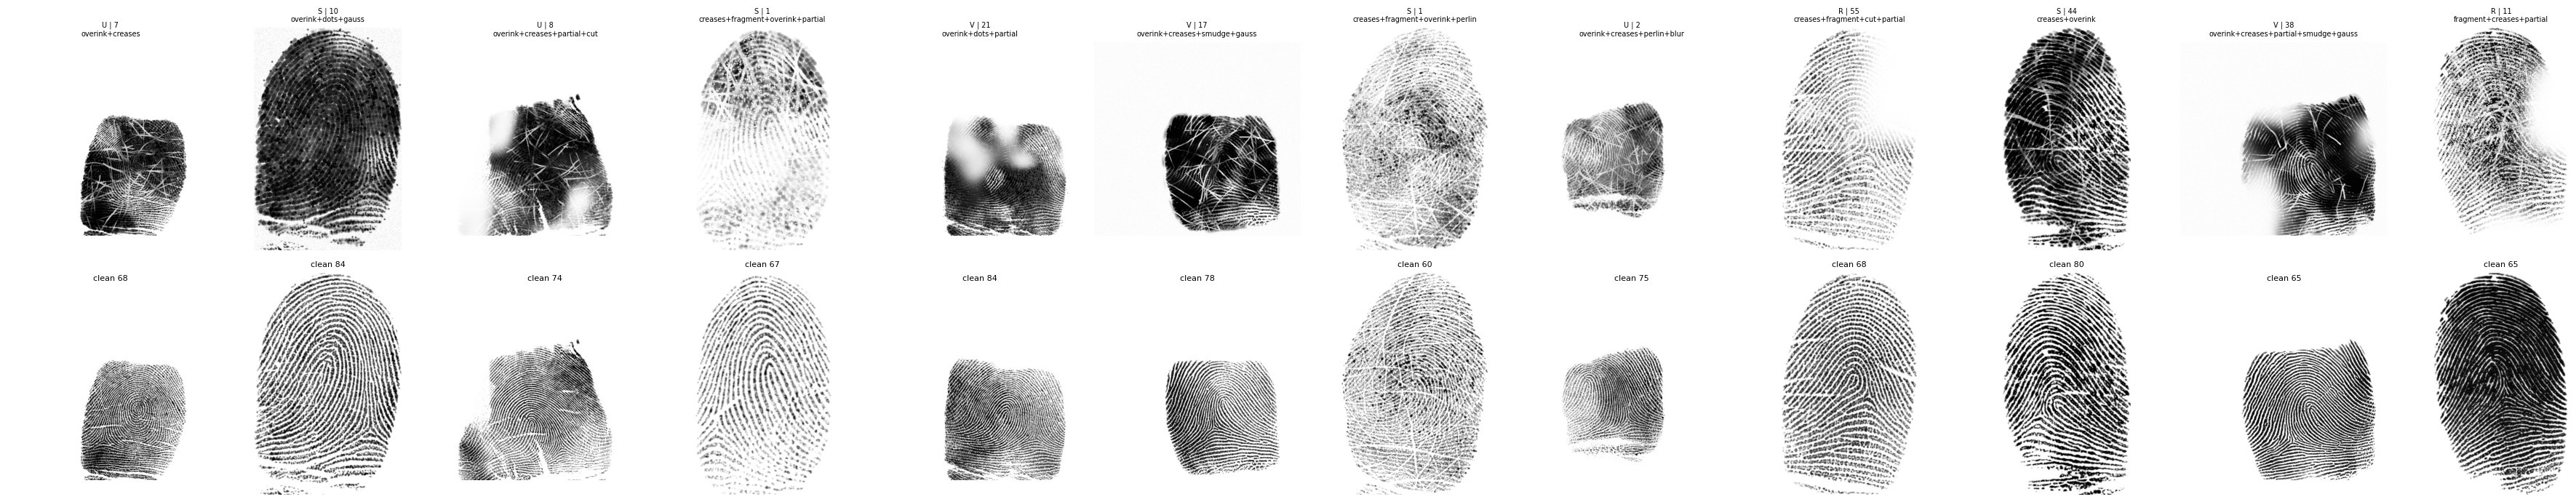

In [ ]:
# VALIDATION
m = pd.read_csv(meta_path, dtype={'key': str, 'participant': str})
m['kept_above30'] = m['kept_above30'].astype(bool)
print("rows:", len(m), "| clean list:", len(clean), "| missing:", len(set(clean['key']) - set(m['key'])),
      "| duplicate keys:", int(m['key'].duplicated().sum()))

# 1) files readable, same shape as clean
bad = []
for _, r in tqdm(m.iterrows(), total=len(m), desc="file check"):
    try:
        a = np.asarray(Image.open(r['noisy_path']).convert('L')); c = np.asarray(Image.open(r['clean_path']).convert('L'))
        if a.shape != c.shape: bad.append((r['key'], 'shape'))
    except Exception as e:
        bad.append((r['key'], repr(e)[:60]))
print("bad files:", len(bad), bad[:5])

# 2) split x device counts and no participant in two splits
print("\n", pd.crosstab(m['device'], m['split']))
assert (m.groupby('participant')['split'].nunique() == 1).all(), "participant leakage"

# 3) severity spread: overall, per device, per split (we want every level present in every split and device)
print("\noverall:"); print(bands(m['noisy_nfiq2']).to_string())
print("\nper device (% of images):")
print(pd.DataFrame({dev: bands(m.loc[m.device == dev, 'noisy_nfiq2']) for dev in sorted(m.device.unique())}).to_string())
print("\nper split (% of images):")
print(pd.DataFrame({sp_: bands(m.loc[m.split == sp_, 'noisy_nfiq2']) for sp_ in sorted(m.split.unique())}).to_string())

# 4) noise usage
print("\nnoise usage:\n", pd.Series([n for s in m['noises'] for n in s.split('+')]).value_counts().to_string())

# 5) reproducibility from stored seed + cfg
same = 0
for _, r in m.sample(min(20, len(m)), random_state=0).iterrows():
    cf = STRONG if r['cfg_used'] == 'STRONG' else Q2
    o, _, _ = make_noisy5(load(r['clean_path']), r['key'], cf, seed=int(r['seed_used']))
    same += int(np.array_equal(o, np.asarray(Image.open(r['noisy_path']).convert('L'))))
print(f"\nreproducible: {same}/{min(20, len(m))} identical")

# 6) 12 pairs: noisy (top), clean target (bottom)
pick = m.sample(min(12, len(m)), random_state=5)
fig, ax = plt.subplots(2, len(pick), figsize=(3 * len(pick), 7), squeeze=False)
for j, (_, r) in enumerate(pick.iterrows()):
    ax[0, j].imshow(Image.open(r['noisy_path']), cmap='gray'); ax[0, j].set_title(f"{r['device']} | {r['noisy_nfiq2']:.0f}\n{r['noises']}", fontsize=7)
    ax[1, j].imshow(Image.open(r['clean_path']), cmap='gray'); ax[1, j].set_title(f"clean {r['clean_nfiq2']:.0f}", fontsize=8)
for a in ax.ravel(): a.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
# freeze the recipe + export
manifest = dict(seed=CFG['seed'], clean_min=CFG['clean_min'], use_target_bands=USE_TARGET_BANDS,
                targets=TARGETS, target_p=TARGET_P, max_try_per_cfg=MAX_TRY,
                order=ORDER + ['gauss'], cfg_Q2=Q2, cfg_STRONG=STRONG, rows=len(m),
                missed_target=int(m['kept_above30'].sum()), noisy_dir=str(NOISY_DIR), split_csv=str(SPLIT_CSV))
(PROJECT / 'noise_manifest_v2.json').write_text(json.dumps(manifest, indent=2))
print("manifest saved")

if LIMIT is None:      # zip only after the FULL run
    shutil.make_archive('/content/drive/MyDrive/NIST/noise_project_v2_export', 'zip',
                        root_dir='/content/drive/MyDrive/NIST', base_dir='noise_project')
    print("zip done")
else:
    print("LIMIT is set (test run): zip skipped")

manifest saved
zip done
